In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse
import gzip

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import euclidean_distances
from sklearn.decomposition import PCA
import matplotlib.colors as mcolors
import matplotlib.cm as cm

import sklearn.cluster as cl
#import hdbscan as hdbscan
import umap
from ismember import ismember


# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-um

In [8]:
#read samples list, raw matrix and organized.
scRNA_5stages_fresh1 = pd.read_csv("/home/xiangru.huo-umw/SSC/Matrix/4DN_5stage_fresh/4DN_fresh_5stages_reads_all_matrix.txt", sep='\t',index_col=0)
scRNA_5stages_index = pd.read_csv("/home/xiangru.huo-umw/SSC/Matrix/4DN_5stage_fresh/4DN_fresh_5stages_barcode_all.txt", sep='\t',index_col=3)
scRNA_5stages_index['orignal.stage']= scRNA_5stages_index['orignal.stage'].str.replace('H1', 'ES')
scRNA_5stages_fresh = scRNA_5stages_fresh1.transpose()
scRNA_5stages_index.index = scRNA_5stages_index.index.str.replace('-', '.', regex=False)
scRNA_5stages_sample = scRNA_5stages_index.loc[:, ['orignal.stage', 'batch']]
scRNA_5stages_sum = pd.merge(scRNA_5stages_fresh, scRNA_5stages_sample, left_index=True,right_index=True)

In [6]:
scRNA_5stages_fresh

,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2,GCLC,NFYA,...,TM4SF19-TCTEX1D2,AC024884.1,AL138995.1,AC099552.4,DUX4L8,FAM138F,AC068544.1,DUX4L32,SULT6B2P,AC009152.3
H1.scRNAfresh.plate1.30,0,0,5,0,1,0,0,0,2,0,...,0,0,0,0,0,0,0,0,0,0
HB.scRNAfresh.plate1.70,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DE.scRNAfresh.plate1.28,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
mHep.scRNAfresh.plate1.36,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
iHep.scRNAfresh.plate2.39,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
iHep.scRNAfresh.plate2.66,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
iHep.scRNAfresh.plate2.55,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
iHep.scRNAfresh.plate2.56,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
iHep.scRNAfresh.plate2.72,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
scRNA_5stages_sample

,orignal.stage,batch
DE.scRNAfresh.plate1.1,DE,1
DE.scRNAfresh.plate1.10,DE,1
DE.scRNAfresh.plate1.11,DE,1
DE.scRNAfresh.plate1.12,DE,1
DE.scRNAfresh.plate1.13,DE,1
...,...,...
mHep.scRNAfresh.plate2.94,mHep,2
mHep.scRNAfresh.plate2.95,mHep,2
mHep.scRNAfresh.plate2.96,mHep,2
HB.scRNAfresh.plate2.91,HB,2


In [8]:
scRNA_5stages_sum

,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2,GCLC,NFYA,...,AL138995.1,AC099552.4,DUX4L8,FAM138F,AC068544.1,DUX4L32,SULT6B2P,AC009152.3,orignal.stage,batch
H1.scRNAfresh.plate1.30,0,0,5,0,1,0,0,0,2,0,...,0,0,0,0,0,0,0,0,ES,1
HB.scRNAfresh.plate1.70,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,HB,1
DE.scRNAfresh.plate1.28,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,DE,1
mHep.scRNAfresh.plate1.36,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,mHep,1
iHep.scRNAfresh.plate2.39,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,iHep,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
iHep.scRNAfresh.plate2.66,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,iHep,2
iHep.scRNAfresh.plate2.55,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,iHep,2
iHep.scRNAfresh.plate2.56,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,iHep,2
iHep.scRNAfresh.plate2.72,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,iHep,2


# Let's convert to counts to tpm

In [13]:
#load the gene length profile
gene_length = pd.read_csv('/home/xiangru.huo-umw/reference/hg38/gencode.v29.annotation.gtf.length.bed',sep="\t",comment="#", 
                       names=['chrom', 'start', 'end', 'length', 'gene', 'dot', 'strand'],index_col=None)
gene_length

,chrom,start,end,length,gene,dot,strand
0,chr1,11869,14409,2540,DDX11L1,.,+
1,chr1,12010,13670,1660,DDX11L1,.,+
2,chr1,14404,29570,15166,WASH7P,.,-
3,chr1,17369,17436,67,MIR6859-1,.,-
4,chr1,29554,31097,1543,MIR1302-2HG,.,+
...,...,...,...,...,...,...,...
206689,chrY,57209306,57210051,745,WASH6P,.,+
206690,chrY,57209887,57212186,2299,WASH6P,.,+
206691,chrY,57210344,57212074,1730,WASH6P,.,+
206692,chrY,57210591,57212074,1483,WASH6P,.,+


In [14]:
#keep the longest length of transcripts and set dictionary
filtered_gene_length = gene_length.groupby('gene').head(1)
filtered_gene_length = filtered_gene_length.set_index('gene')['length']

In [15]:
#convert counts to tpm
def counts_to_tpm(counts_matrix):
    """
    Convert UMI counts matrix to TPM matrix, incorporating gene lengths.
    
    Parameters:
    counts_matrix (pd.DataFrame): DataFrame where rows are cells and columns are genes with UMI counts.
    
    Returns:
    pd.DataFrame: TPM matrix where rows are cells and columns are genes.
    """
    # Ensure the gene names in the counts matrix and the gene lengths match
    matched_genes = counts_matrix.columns.intersection(filtered_gene_length.index)
    counts_matrix = counts_matrix[matched_genes]
    gene_lengths = filtered_gene_length[matched_genes]
    
    # Step 1: Normalize by gene length to get RPK (Reads Per Kilobase)
    rpk = counts_matrix.div(gene_lengths, axis=1) * 1e3
    
    # Step 2: Calculate total RPK per cell
    total_rpk_per_cell = rpk.sum(axis=1)
    
    # Step 3: Calculate TPM
    tpm = rpk.div(total_rpk_per_cell, axis=0) * 1e6
    
    # Round TPM values to 3 decimal places (adjust as needed)
    tpm = tpm.round(3)
    
    return tpm

In [17]:
#apply tpm converted function to gene counts matrix 
tpm_matrix = {}
tpm_matrix['ES'] = counts_to_tpm(ES_info)
tpm_matrix['DE'] = counts_to_tpm(DE_info)
tpm_matrix['HB'] = counts_to_tpm(HB_info)
tpm_matrix['iHep'] = counts_to_tpm(iHep_info)
tpm_matrix['mHep'] = counts_to_tpm(mHep_info)
tpm_matrix['Hap1'] = counts_to_tpm(Hap1_info)
tpm_matrix['K562'] = counts_to_tpm(K562_info)
tpm_matrix['Hap1&K562'] = counts_to_tpm(benchmarktwocells)

tpm_matrix['whole_matrix'] = counts_to_tpm(scRNA_5stages_fresh1.transpose())

# fit the standard negative binomial regression: Var(X)=μ+ μ^2/θ manually
Manually fitting is quite good; try to use the z-scaled dispersion and residual variance from Seurat

In [18]:
#z-score dispersion
def variance_table_zscore_dispersion(matrix, n_bins=200):
    df = pd.DataFrame()
    df['mean'] = matrix.mean(axis=1)
    df['variance'] = matrix.var(axis=1, ddof=1)
    df['dispersion'] = df['variance'] / df['mean'].replace(0, np.nan)
    df['log_dispersion'] = np.log1p(df['dispersion'])

    # Bin genes by mean
    df['mean_bin'] = pd.qcut(df['mean'].rank(method='first'), q=n_bins, duplicates='drop')

    # Z-score dispersion within each bin
    df['dispersion_z'] = df.groupby('mean_bin')['log_dispersion'].transform(
        lambda x: (x - x.mean()) / x.std(ddof=1)
    )
    return df.drop(columns=['mean_bin'])

In [19]:
#standard negative binomial regression: Var(X)=μ+ μ^2/θ
import statsmodels.api as sm
def variance_table_overdispersion_nb(matrix):
    df = pd.DataFrame()
    df['mean'] = matrix.mean(axis=1)
    df['variance'] = matrix.var(axis=1, ddof=1)

    # Fit NB model: variance = mean + alpha * mean^2
    X = np.column_stack([df['mean'], df['mean'] ** 2])
    X = sm.add_constant(X)  # Adds intercept term
    model = sm.OLS(df['variance'], X, missing='drop').fit()
    
    # Predict expected variance
    df['expected_var'] = model.predict(X)
    df['overdispersion'] = df['variance'] / df['expected_var'].replace(0, np.nan)
    
    return df

In [20]:
#apply the variance calculation on UMI_matrix. 
# Transpose TPM matrix (stage 'ES') to genes x cells
tpm_matrix_T = tpm_matrix['whole_matrix'].transpose()

# Define UMI matrix (already in genes x cells format)
UMI_matrix = scRNA_5stages_fresh1

# ---- TPM-based variance tables ----
zscore_table_TPM = variance_table_zscore_dispersion(tpm_matrix_T)
nb_table_TPM = variance_table_overdispersion_nb(tpm_matrix_T)

# Merge TPM variance tables with appropriate suffixes
variance_table_TPM = zscore_table_TPM \
    .join(nb_table_TPM[['expected_var', 'overdispersion']].rename(columns={
        'expected_var': 'expected_var_nb',
        'overdispersion': 'overdispersion_nb'
    })) 

# ---- UMI-based variance tables ----
zscore_table_UMI = variance_table_zscore_dispersion(UMI_matrix)
nb_table_UMI = variance_table_overdispersion_nb(UMI_matrix)

# Merge results into a single variance table for UMI
variance_table_UMI = zscore_table_UMI \
    .join(nb_table_UMI[['expected_var', 'overdispersion']].rename(columns={
        'expected_var': 'expected_var_nb',
        'overdispersion': 'overdispersion_nb'
    }))

In [21]:
variance_table_UMI

,mean,variance,dispersion,log_dispersion,dispersion_z,expected_var_nb,overdispersion_nb
TSPAN6,1.173178,18.963635,16.164323,2.842833,-0.888809,39655.429531,4.782103e-04
TNMD,0.096093,1.103864,11.487466,2.524725,0.158825,-20357.964933,-5.422272e-05
DPM1,1.889124,49.724480,26.321455,3.307672,-0.671006,79547.111850,6.250947e-04
SCYL3,0.062302,0.212816,3.415881,1.485207,-1.206942,-22240.725636,-9.568764e-06
C1orf112,0.395987,7.605185,19.205626,3.005961,-0.198298,-3648.430487,-2.084509e-03
...,...,...,...,...,...,...,...
FAM138F,0.001056,0.001056,1.000000,0.693147,-0.213788,-25653.227479,-4.116309e-08
AC068544.1,0.001056,0.001056,1.000000,0.693147,-0.213788,-25653.227479,-4.116309e-08
DUX4L32,0.001056,0.001056,1.000000,0.693147,-0.213788,-25653.227479,-4.116309e-08
SULT6B2P,0.001056,0.001056,1.000000,0.693147,-0.213788,-25653.227479,-4.116309e-08


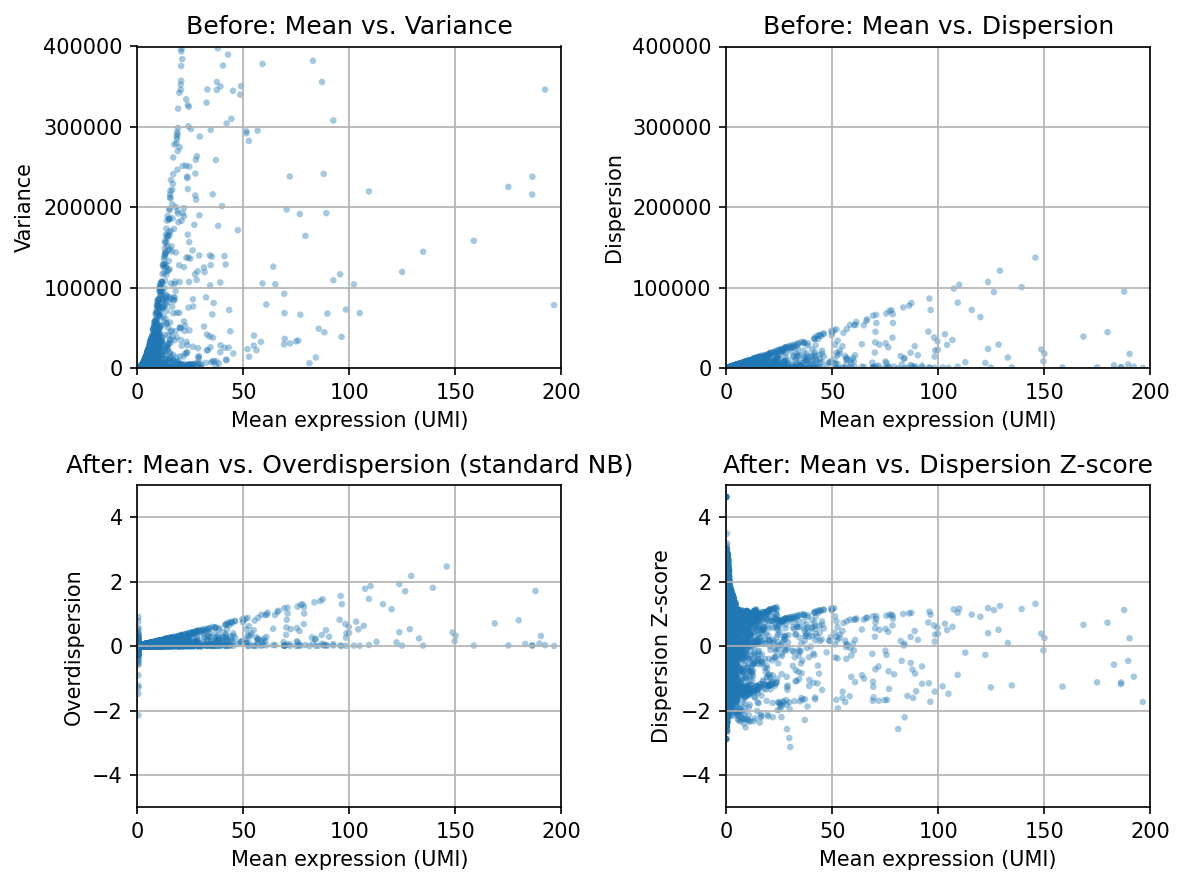

In [ ]:
#plot variance corrected results in UMI matrix
# Create figure and axes
fig, axs = plt.subplots(2, 2, figsize=(8, 6), dpi=150)

# ---- Plot 1 ----
axs[0, 0].scatter(variance_table_UMI['mean'], variance_table_UMI['variance'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[0, 0].set_title('Before: Mean vs. Variance')
axs[0, 0].set_xlabel('Mean expression (UMI)')
axs[0, 0].set_ylabel('Variance')
axs[0, 0].set_xlim(0, 200)
axs[0, 0].set_ylim(0, 400000)
axs[0, 0].grid(True)
fig.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Correction_UMI_1.pdf", 
            format="pdf", bbox_inches="tight")

# ---- Plot 2 ----
axs[0, 1].scatter(variance_table_UMI['mean'], variance_table_UMI['dispersion'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[0, 1].set_title('Before: Mean vs. Dispersion')
axs[0, 1].set_xlabel('Mean expression (UMI)')
axs[0, 1].set_ylabel('Dispersion')
axs[0, 1].set_xlim(0, 200)
axs[0, 1].set_ylim(-100, 400000)
axs[0, 1].grid(True)
fig.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Correction_UMI_2.pdf", 
            format="pdf", bbox_inches="tight")

# ---- Plot 3 ----
axs[1, 0].scatter(variance_table_UMI['mean'], variance_table_UMI['overdispersion_nb'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[1, 0].set_title('After: Mean vs. Overdispersion (standard NB)')
axs[1, 0].set_xlabel('Mean expression (UMI)')
axs[1, 0].set_ylabel('Overdispersion')
axs[1, 0].set_xlim(0, 200)
axs[1, 0].set_ylim(-5, 5)
axs[1, 0].grid(True)
fig.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Correction_UMI_3.pdf", 
            format="pdf", bbox_inches="tight")

# ---- Plot 4 ----
axs[1, 1].scatter(variance_table_UMI['mean'], variance_table_UMI['dispersion_z'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[1, 1].set_title('After: Mean vs. Dispersion Z-score')
axs[1, 1].set_xlabel('Mean expression (UMI)')
axs[1, 1].set_ylabel('Dispersion Z-score')
axs[1, 1].set_xlim(0, 200)
axs[1, 1].set_ylim(-5, 5)
axs[1, 1].grid(True)
fig.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Correction_UMI_4.pdf", 
            format="pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()

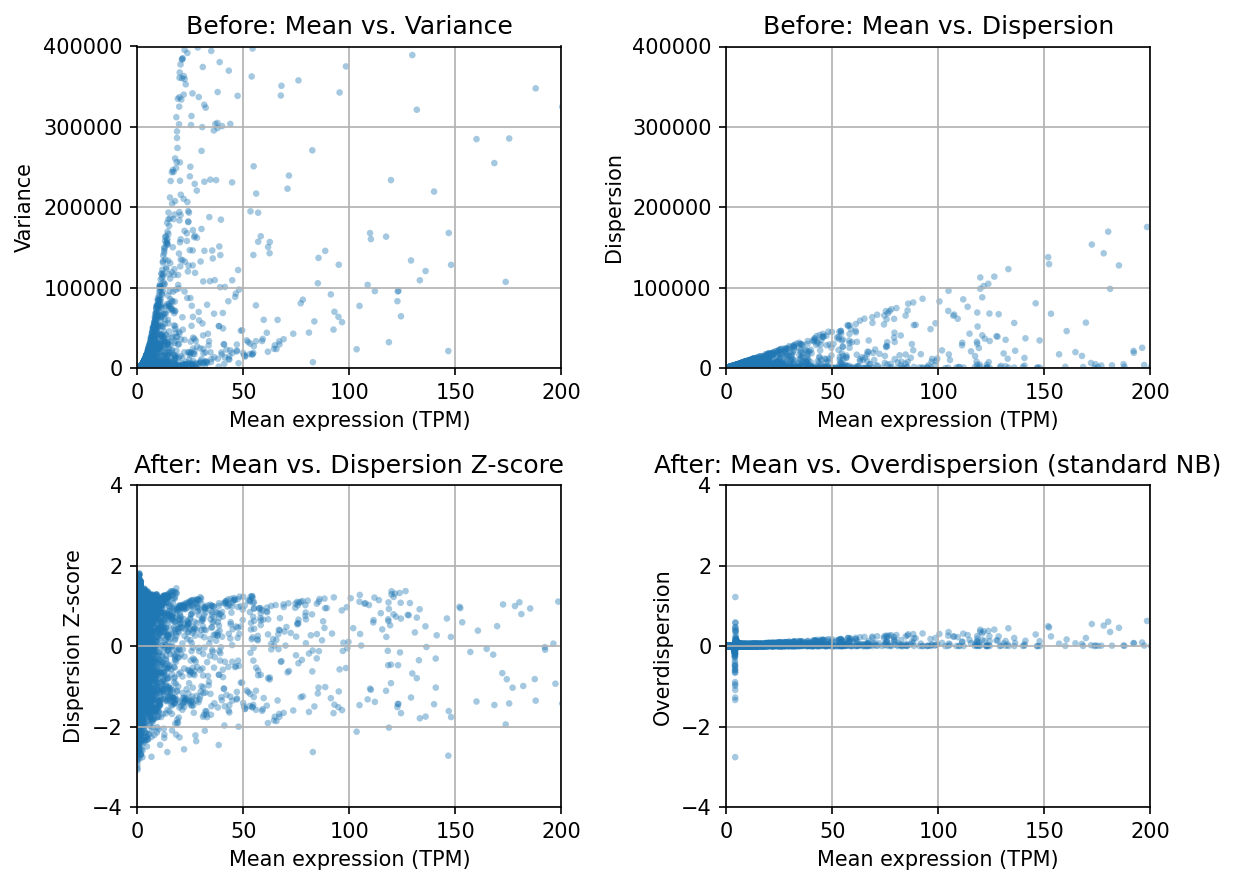

In [ ]:
#plot variance corrected results in TPM matrix
fig, axs = plt.subplots(2, 2, figsize=(8, 6),dpi = 150)

# Plot 1: Mean vs. Variance
axs[0, 0].scatter(variance_table_TPM['mean'], variance_table_TPM['variance'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[0, 0].set_title('Before: Mean vs. Variance')
axs[0, 0].set_xlabel('Mean expression (TPM)')
axs[0, 0].set_ylabel('Variance')
axs[0, 0].set_xlim(0, 200)
axs[0, 0].set_ylim(0, 400000)
axs[0, 0].grid(True)

# Plot 2: Mean vs. Dispersion
axs[0, 1].scatter(variance_table_TPM['mean'], variance_table_TPM['dispersion'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[0, 1].set_title('Before: Mean vs. Dispersion')
axs[0, 1].set_xlabel('Mean expression (TPM)')
axs[0, 1].set_ylabel('Dispersion')
axs[0, 1].set_xlim(0, 200)
axs[0, 1].set_ylim(-100, 400000)
axs[0, 1].grid(True)

# Plot 3: Mean vs. Dispersion Z-score
axs[1, 0].scatter(variance_table_TPM['mean'], variance_table_TPM['dispersion_z'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[1, 0].set_title('After: Mean vs. Dispersion Z-score')
axs[1, 0].set_xlabel('Mean expression (TPM)')
axs[1, 0].set_ylabel('Dispersion Z-score')
axs[1, 0].set_xlim(0, 200)
axs[1, 0].set_ylim(-4, 4)
axs[1, 0].grid(True)

# Plot 4: Mean vs. Overdispersion
axs[1, 1].scatter(variance_table_TPM['mean'], variance_table_TPM['overdispersion_nb'], 
                  alpha=0.4, s=10, edgecolor='none')
axs[1, 1].set_title('After: Mean vs. Overdispersion (standard NB)')
axs[1, 1].set_xlabel('Mean expression (TPM)')
axs[1, 1].set_ylabel('Overdispersion')
axs[1, 1].set_xlim(0, 200)
axs[1, 1].set_ylim(-4, 4)
axs[1, 1].grid(True)

plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Correction(tpm).pdf", 
            format="pdf", bbox_inches="tight")

plt.show()

# get the z-scaled dispersion and pearson-residuals from Seurat

In [26]:
#load the variance table get from Seurat
# 1. Load SCTransform residuals (all cells together)
SCT_residue_whole_allgene = pd.read_csv(
    '/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/SCT_residuals_matrix_allgene.csv',
    index_col=0
)

# 2. Load SCTransform residuals (5 stages separately)
SCT_residue_whole = pd.read_csv(
    '/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/SCT_residuals_matrix.csv',
    index_col=0
)

# 3. Load vst dispersion whole matrix (z-scored log dispersion)
z_scored_dispersion_whole = pd.read_csv(
    '/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/vst_dispersion_wholematrix.csv',
    index_col=None  # Keep all columns, including 'gene' and 'stage'
)

# 4. Load vst dispersion by stage (z-scored log dispersion)
z_scored_dispersion = pd.read_csv(
    '/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/vst_dispersion_by_stage.csv',
    index_col=None  # Keep all columns, including 'gene' and 'stage'
)

In [28]:
 zscore_table_UMI_sum.reset_index()

,index,stage,mean,variance,dispersion,log_dispersion,dispersion_z
0,TSPAN6,H1,1.173178,18.963635,16.164323,2.842833,-0.888809
1,TNMD,H1,0.096093,1.103864,11.487466,2.524725,0.158825
2,DPM1,H1,1.889124,49.724480,26.321455,3.307672,-0.671006
3,SCYL3,H1,0.062302,0.212816,3.415881,1.485207,-1.206942
4,C1orf112,H1,0.395987,7.605185,19.205626,3.005961,-0.198298
...,...,...,...,...,...,...,...
181945,FAM138F,mHep,0.001056,0.001056,1.000000,0.693147,-0.213788
181946,AC068544.1,mHep,0.001056,0.001056,1.000000,0.693147,-0.213788
181947,DUX4L32,mHep,0.001056,0.001056,1.000000,0.693147,-0.213788
181948,SULT6B2P,mHep,0.001056,0.001056,1.000000,0.693147,-0.213788


In [29]:
#merge z_scored_dispersion and zscore_table_UMI_sum together
# Step 1: Reset index to bring 'gene' into a column
#zscore_table_UMI_sum.index.name = 'gene'
zscore_table_UMI_sum_reset = zscore_table_UMI_sum.reset_index(names='gene')  # 'gene' becomes a column

# Step 2: Merge on both 'gene' and 'stage'
z_scored_dispersion_merge = pd.merge(
    zscore_table_UMI_sum_reset,
    z_scored_dispersion,
    on=['gene', 'stage'],
    how='inner'  # or 'outer' or 'left' as needed
)

In [30]:
z_scored_dispersion_merge

,gene,stage,mean,variance,dispersion,log_dispersion,dispersion_z,vst.mean,vst.variance,vst.variance.expected,vst.variance.standardized
0,TSPAN6,H1,1.173178,18.963635,16.164323,2.842833,-0.888809,6.066667,69.604469,172.845081,0.402699
1,TNMD,H1,0.096093,1.103864,11.487466,2.524725,0.158825,0.505556,5.625667,4.964691,1.133135
2,DPM1,H1,1.889124,49.724480,26.321455,3.307672,-0.671006,9.850000,183.267877,490.822502,0.373389
3,SCYL3,H1,0.062302,0.212816,3.415881,1.485207,-1.206942,0.255556,0.817008,1.954740,0.417962
4,C1orf112,H1,0.395987,7.605185,19.205626,3.005961,-0.198298,1.877778,34.688889,27.227295,1.274048
...,...,...,...,...,...,...,...,...,...,...,...
161165,KRTAP10-9,mHep,0.002112,0.002110,0.998943,0.692618,-0.616807,0.011429,0.011363,NaN,NaN
161166,AC112492.2,mHep,0.003168,0.009504,3.000000,1.386294,1.362303,0.017143,0.051429,0.019065,1.021162
161167,AL034346.1,mHep,0.002112,0.002110,0.998943,0.692618,-0.616807,0.011429,0.011363,NaN,NaN
161168,SMCO4P1,mHep,0.002112,0.002110,0.998943,0.692618,-0.616807,0.005714,0.005714,NaN,NaN


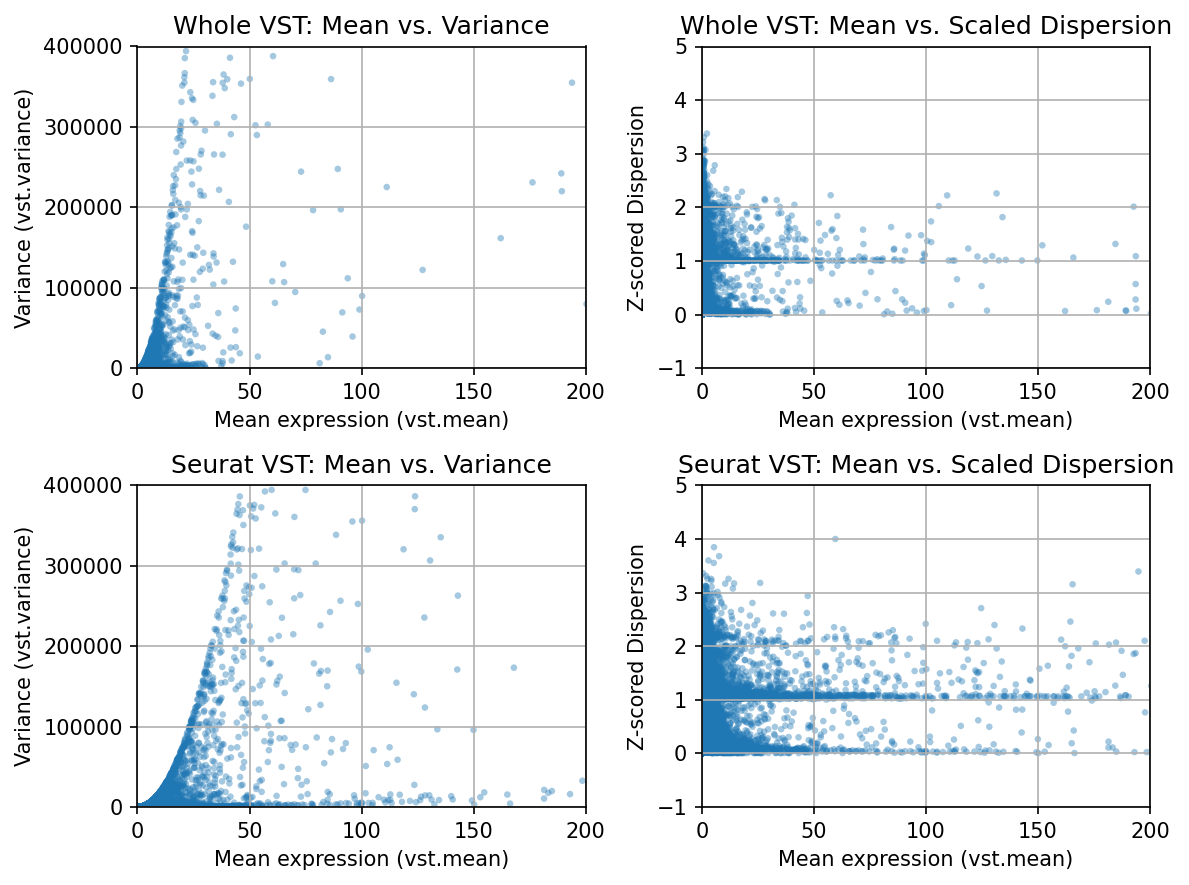

In [ ]:
# Create the 2x2 subplot layout
fig, axs = plt.subplots(2, 2, figsize=(8, 6),dpi = 150)

# Plot 1: Mean vs. Variance
axs[0, 0].scatter(z_scored_dispersion_whole['vst.mean'], z_scored_dispersion_whole['vst.variance'], 
               alpha=0.4, s=10, edgecolor='none')
axs[0, 0].set_title('Whole VST: Mean vs. Variance')
axs[0, 0].set_xlabel('Mean expression (vst.mean)')
axs[0, 0].set_ylabel('Variance (vst.variance)')
axs[0, 0].set_xlim(0, 200)
axs[0, 0].set_ylim(0, 400000)
axs[0, 0].grid(True)

# Plot 2: Mean vs. Scaled Dispersion
axs[0, 1].scatter(z_scored_dispersion_whole['vst.mean'], z_scored_dispersion_whole['vst.variance.standardized'], 
               alpha=0.4, s=10, edgecolor='none')
axs[0, 1].set_title('Whole VST: Mean vs. Scaled Dispersion')
axs[0, 1].set_xlabel('Mean expression (vst.mean)')
axs[0, 1].set_ylabel('Z-scored Dispersion')
axs[0, 1].set_xlim(0, 200)
axs[0, 1].set_ylim(-1, 5)
axs[0, 1].grid(True)

# Plot 3: Mean vs. Variance
axs[1, 0].scatter(z_scored_dispersion['vst.mean'], z_scored_dispersion['vst.variance'], 
               alpha=0.4, s=10, edgecolor='none')
axs[1, 0].set_title('Seurat VST: Mean vs. Variance')
axs[1, 0].set_xlabel('Mean expression (vst.mean)')
axs[1, 0].set_ylabel('Variance (vst.variance)')
axs[1, 0].set_xlim(0, 200)
axs[1, 0].set_ylim(0, 400000)
axs[1, 0].grid(True)

# Plot 4: Mean vs. Scaled Dispersion
axs[1, 1].scatter(z_scored_dispersion['vst.mean'], z_scored_dispersion['vst.variance.standardized'], 
               alpha=0.4, s=10, edgecolor='none')
axs[1, 1].set_title('Seurat VST: Mean vs. Scaled Dispersion')
axs[1, 1].set_xlabel('Mean expression (vst.mean)')
axs[1, 1].set_ylabel('Z-scored Dispersion')
axs[1, 1].set_xlim(0, 200)
axs[1, 1].set_ylim(-1, 5)
axs[1, 1].grid(True)


plt.tight_layout()

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Corrected_zsored_dispersion(seurat).pdf", 
            format="pdf", bbox_inches="tight")

plt.show()

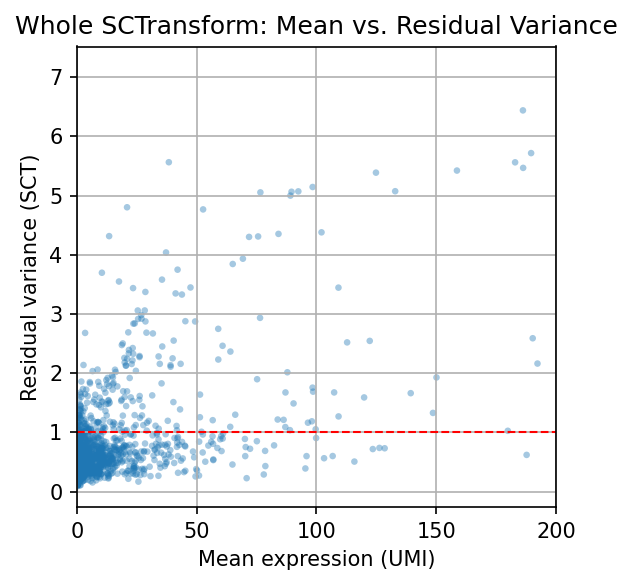

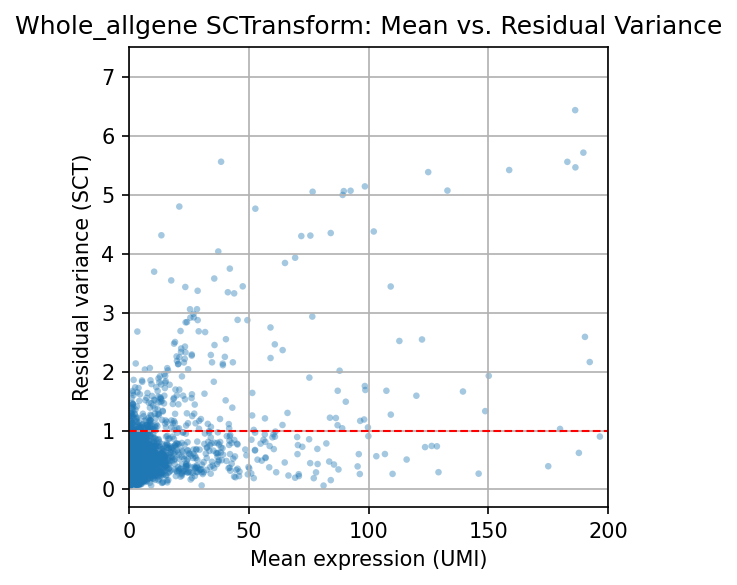

In [31]:
#mean VS SCT residues

# Function to compute and plot mean vs. residual variance
def plot_residual_variance(sct_residuals, umi_matrix, title):
    # 1. Compute gene-wise mean expression and residual variance
    gene_means = umi_matrix.mean(axis=1)
    gene_residual_variance = sct_residuals.var(axis=1, ddof=1)

    # 2. Combine into DataFrame and filter
    df = pd.DataFrame({
        'mean_expression': gene_means,
        'residual_variance': gene_residual_variance
    })
    df = df[df['mean_expression'] > 0.1]

    # 3. Plot
    plt.figure(figsize=(4, 4),dpi = 150)
    plt.scatter(df['mean_expression'], df['residual_variance'],
                alpha=0.4, s=10, edgecolor='none')

    # Add horizontal reference line at y = 1
    plt.axhline(y=1, color='red', linestyle='--', linewidth=1)

    plt.xlabel("Mean expression (UMI)")
    plt.ylabel("Residual variance (SCT)")
    plt.title(title)
    plt.xlim(0, 200)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Corrected_ResidualVariance(seurat).pdf", 
            format="pdf", bbox_inches="tight")

    plt.show()
    
# 🔹 Plot for SCT_residue_whole
plot_residual_variance(SCT_residue_whole, scRNA_5stages_fresh1, 
                       title="Whole SCTransform: Mean vs. Residual Variance")

plot_residual_variance(SCT_residue_whole_allgene, scRNA_5stages_fresh1, 
                       title="Whole_allgene SCTransform: Mean vs. Residual Variance")

In [32]:
#pearson residuals colored by stages
# Step 1: Convert both column names to dot-format (standard format)
SCT_residue_whole_allgene.columns = SCT_residue_whole_allgene.columns.str.replace('-', '.', regex=False)
scRNA_5stages_fresh1.columns = scRNA_5stages_fresh1.columns.str.replace('-', '.', regex=False)

# Step 2: Extract stage
cell_stage = SCT_residue_whole_allgene.columns.str.split('.').str[0]
stage_map = dict(zip(SCT_residue_whole_allgene.columns, cell_stage))

# Step 3: Group and calculate
SCT_residue_by_stage = {
    stage: [cell for cell in SCT_residue_whole_allgene.columns if stage_map[cell] == stage]
    for stage in set(cell_stage)
}

mean_residual_df = []
for stage, cells in SCT_residue_by_stage.items():
    sct_sub = SCT_residue_whole_allgene[cells]
    umi_sub = scRNA_5stages_fresh1[cells]  # ✅ should now work

    gene_means = umi_sub.mean(axis=1)
    gene_res_var = sct_sub.var(axis=1, ddof=1)

    df = pd.DataFrame({
        'mean_expression': gene_means,
        'residual_variance': gene_res_var,
        'stage': stage
    })
    mean_residual_df.append(df)

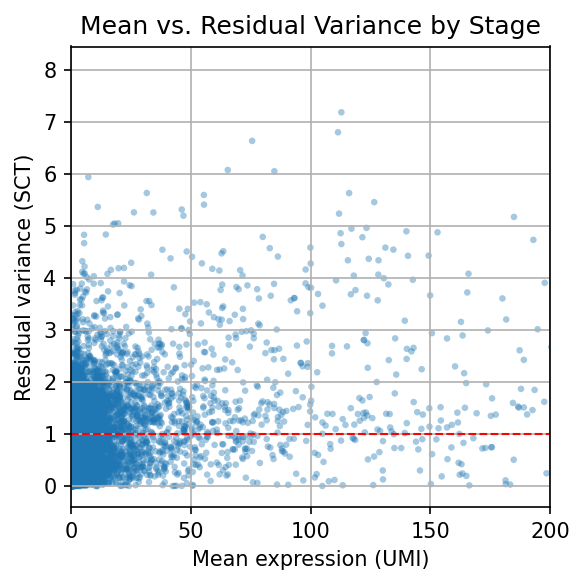

In [46]:
#plot
plt.figure(figsize=(4, 4), dpi=150)

# Plot all points in default blue
plt.scatter(
    plot_df['mean_expression'],
    plot_df['residual_variance'],
    s=10,
    alpha=0.4,
    edgecolor='none'
)

# Aesthetics
plt.axhline(y=1, color='red', linestyle='--', linewidth=1)
plt.xlabel("Mean expression (UMI)")
plt.ylabel("Residual variance (SCT)")
plt.title("Mean vs. Residual Variance by Stage")
plt.xlim(0, 200)
plt.grid(True)
plt.tight_layout()

plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Variance_expression_Corrected_ResidualVariance_singlecolor.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

In [56]:
#plot violin plot to see the global trend of pearson residual across five stages. 
# Step 1: Standardize column names
SCT_residue_whole_allgene.columns = SCT_residue_whole_allgene.columns.str.replace('-', '.', regex=False)
scRNA_5stages_fresh1.columns = scRNA_5stages_fresh1.columns.str.replace('-', '.', regex=False)

# Step 2: Extract stage labels
cell_stage = SCT_residue_whole_allgene.columns.str.split('.').str[0]
stage_map = dict(zip(SCT_residue_whole_allgene.columns, cell_stage))

# Step 3: Group columns by stage
SCT_residue_by_stage = {
    stage: [cell for cell in SCT_residue_whole_allgene.columns if stage_map[cell] == stage]
    for stage in sorted(set(cell_stage))
}

# Step 4: Compute mean & residual variance per gene, per stage
mean_residual_df = []

for stage, cells in SCT_residue_by_stage.items():
    sct_sub = SCT_residue_whole_allgene[cells]
    umi_sub = scRNA_5stages_fresh1[cells]

    gene_means = umi_sub.mean(axis=1)
    gene_res_var = sct_sub.var(axis=1, ddof=1)

    # Align and drop any rows with missing values
    combined = pd.concat([gene_means, gene_res_var], axis=1, join='inner')
    combined.columns = ['mean_expression', 'residual_variance']
    combined['gene'] = combined.index
    combined['stage'] = stage

    mean_residual_df.append(combined)

# Combine all stages
res_var_df = pd.concat(mean_residual_df, ignore_index=True)

In [57]:
res_var_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/scRNA_residual_variance_summary.csv")
res_var_df

,mean_expression,residual_variance,gene,stage
0,0.057895,0.004682,TSPAN6,DE
1,0.000000,0.000547,TNMD,DE
2,0.015789,0.001238,DPM1,DE
3,0.015789,0.201368,SCYL3,DE
4,0.010526,0.002007,C1orf112,DE
...,...,...,...,...
114995,0.000000,0.000213,FSCN1P1,mHep
114996,0.034286,0.998696,AL138916.2,mHep
114997,0.022857,0.703749,AL109659.3,mHep
114998,0.017143,0.531473,RN7SKP163,mHep


In [ ]:
#save the table
res_var_df.to_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/scRNAresidual_variance_summary.csv", index=False)

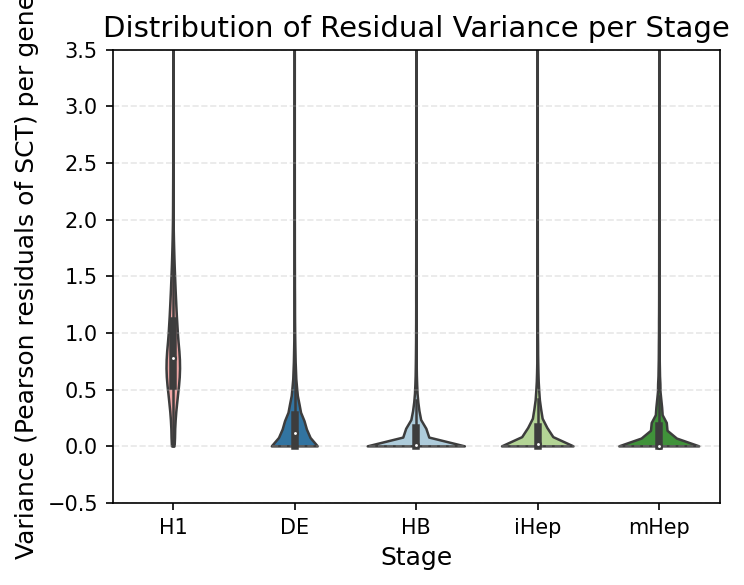

In [29]:
#plot violin plot to see the global trend of pearson residual across five stages. 

#plot violin plot to see the global trend
# Define the order of stages for the x-axis
stage_order = ['H1', 'DE', 'HB', 'iHep', 'mHep']

# Define your custom palette (example Paired colors)
paired_palette = sns.color_palette("Paired")
custom_palette = {
    "HB": paired_palette[0],
    "DE": paired_palette[1],
    "iHep": paired_palette[2],
    "mHep": paired_palette[3],
    "H1": paired_palette[4],  # Moved to first in order
}

# Filter the dataframe to include only the 5 specified stages
res_var_df_filtered = res_var_df[res_var_df['stage'].isin(stage_order)]

# Plot with updated aesthetics
plt.figure(figsize=(5, 4),dpi = 150)
sns.violinplot(
    data=res_var_df_filtered,
    x='stage',
    y='residual_variance',
    order=stage_order,
    palette=custom_palette,
    inner='box',
    cut=0, 
    linewidth=1.2
)

# Aesthetics
plt.title("Distribution of Residual Variance per Stage", fontsize=14)
plt.xlabel("Stage", fontsize=12)
plt.ylabel("Variance (Pearson residuals of SCT) per gene", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim (-0.5,3.5)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Violinplot_Variance_expression_Corrected_ResidualVariance_coloredbystage(seurat_allgene).pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

# organize pearson_residual, z-scored dispersion with cis/total ratio, trans count of model, bulk RNA-seq together. 

In [49]:
#read the gene tss table
file_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/filtered_gene_tss.bed'
# Read the .bed file into a DataFrame
gene_tss = pd.read_csv(file_path, sep='\t', index_col=0)
gene_tss

,chrom,start,end,gene,dot,strand
0,chr1,11868,11869,DDX11L1,.,+
1,chr1,17435,17436,MIR6859-1,.,-
2,chr1,29553,29554,MIR1302-2HG,.,+
3,chr1,29569,29570,WASH7P,.,-
4,chr1,30365,30366,MIR1302-2,.,+
...,...,...,...,...,...,...
57128,chrY,57016095,57016096,AMD1P2,.,-
57129,chrY,57165844,57165845,ELOCP24,.,-
57130,chrY,57172768,57172769,TRPC6P,.,-
57131,chrY,57203356,57203357,WASIR1,.,-


In [50]:
#read the binID table (with EGV1)
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

# Create a dictionary to hold the DataFrames
comp_bin_dfs = {}

# Loop through each stage and read the corresponding file
for stage in stages:
    # Construct the file path using the stage value
    file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_EGV_{stage}_1M.txt'
    
    # Read the file into a DataFrame
    comp_bin_dfs[stage] = pd.read_csv(file_path, sep='\t', index_col=0)

In [51]:
#intersect gene_tss with binID table
gene_tss_binID = {}
for stage in stages:
    df1 = gene_tss
    df2 = comp_bin_dfs[stage].copy()
    gene_tss_binID [stage] = bf.overlap(df1,df2, how='left', suffixes=('_1','_2'))
    gene_tss_binID [stage].index = gene_tss_binID [stage]['gene_1']

In [52]:
#read comp_bin_cisratio _normalized into .csv (needs to take care 1M or 2M)
stages2 = ['ES', 'DE', 'HB', 'iHep', 'mHep']
comp_bin_cisratio = {}
# Read each CSV file into a DataFrame and store it in the stage_cis_ratio_Bin_ID_sum dictionary
for stage in stages2:
    file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_{stage}_1M_noH1batch3.txt'
    df = pd.read_csv(file_path, sep='\t',index_col=0)
    comp_bin_cisratio[stage] = df

In [53]:
comp_bin_cisratio[stage]

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum,cis_counts_S.D.,total_counts_S.D.
Bin_ID,,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.565381,0.162607,0.287606,35.526316,1350.0,19.162718,22.582865
chr1_Bin1,chr1,1000000,2000000,1.553887,0.853495,0.104877,0.122879,35.926829,1473.0,24.762851,29.316710
chr1_Bin2,chr1,2000000,3000000,0.671571,0.890096,0.079970,0.089844,43.000000,1763.0,32.504596,36.004861
chr1_Bin3,chr1,3000000,4000000,0.513393,0.909117,0.082616,0.090875,36.195122,1484.0,25.344817,29.094862
chr1_Bin4,chr1,4000000,5000000,-0.206001,0.896039,0.079658,0.088900,47.170732,1934.0,34.764381,39.298157
...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN


In [58]:
#get a table of which bin does these gene belongs to, and merge together
# Harmonize H1 to ES in stage labels
res_var_df['stage'] = res_var_df['stage'].replace({'H1': 'ES'})
#z_scored_dispersion_merge['stage'] = z_scored_dispersion_merge['stage'].replace({'H1': 'ES'})

# Define the stages to process
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
gene_bin_selected = {}
gene_bin_match = {}

for stage in stages:
    # Filter and prepare dispersion-related data
    df = res_var_df[res_var_df['stage'] == stage].copy()
    df.index = df['gene']

#    df2 = z_scored_dispersion_merge[z_scored_dispersion_merge['stage'] == stage].copy()
#    df2.index = df2['gene']

    # Get cisratio bin-level data
    dff = comp_bin_cisratio[stage].copy()

    # Intersect to get genes with TSS bin info
    common_genes = df.index.intersection(gene_tss_binID[stage].index)
    df3 = gene_tss_binID[stage].loc[common_genes, ['E1_2', 'Bin_ID_2']].rename(
        columns={'E1_2': 'E1', 'Bin_ID_2': 'Bin_ID'}
    )

    # Merge: keep all genes from df (left DataFrame)
#    df_combined = pd.merge(df, df2, left_index=True, right_index=True, how='left')
#    df4 = pd.merge(df_combined, df3, left_index=True, right_index=True, how='left')
    df4 = pd.merge(df, df3, left_index=True, right_index=True, how='left')

    # Set Bin_ID as index and drop duplicated E1 column
    df4.index = df4['Bin_ID']
    df4 = df4.drop(columns=['E1'], errors='ignore')

    # Merge with bin-level cis-ratio data
    df5 = pd.merge(df4, dff, left_index=True, right_index=True, how='left')

    # Store final merged DataFrame and a gene-bin map
    gene_bin_selected[stage] = df5
    gene_bin_match[stage] = df5[['Bin_ID', 'gene']].copy()
    gene_bin_selected[stage].to_csv(f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_structure_variance_{stage}.txt", sep='\t', index=False)

In [59]:
gene_bin_selected['ES']

,mean_expression,residual_variance,gene,stage,Bin_ID,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum,cis_counts_S.D.,total_counts_S.D.
Bin_ID,,,,,,,,,,,,,,,,
chrX_Bin100,6.066667,1.404501,TSPAN6,ES,chrX_Bin100,chrX,100000000.0,101000000.0,0.202322,0.735603,0.208535,0.283489,11.301205,938.0,4.457887,13.895722
chrX_Bin100,0.505556,1.196228,TNMD,ES,chrX_Bin100,chrX,100000000.0,101000000.0,0.202322,0.735603,0.208535,0.283489,11.301205,938.0,4.457887,13.895722
chr20_Bin50,9.850000,1.953186,DPM1,ES,chr20_Bin50,chr20,50000000.0,51000000.0,0.549069,0.738195,0.170488,0.230953,20.313253,1686.0,8.582130,12.994302
chr1_Bin169,0.255556,0.583720,SCYL3,ES,chr1_Bin169,chr1,169000000.0,170000000.0,-0.302363,0.809583,0.172691,0.213308,14.614458,1213.0,7.094509,11.136439
chr1_Bin169,1.877778,1.586675,C1orf112,ES,chr1_Bin169,chr1,169000000.0,170000000.0,-0.302363,0.809583,0.172691,0.213308,14.614458,1213.0,7.094509,11.136439
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chr15_Bin34,0.000000,0.000319,FSCN1P1,ES,chr15_Bin34,chr15,34000000.0,35000000.0,0.302969,0.764442,0.163877,0.214374,13.807229,1146.0,7.079395,11.849110
chr6_Bin146,0.000000,0.000261,AL138916.2,ES,chr6_Bin146,chr6,146000000.0,147000000.0,-0.604965,0.847439,0.144279,0.170253,14.192771,1178.0,7.809158,10.125382
chr1_Bin48,0.000000,0.000319,AL109659.3,ES,chr1_Bin48,chr1,48000000.0,49000000.0,-0.320688,0.810132,0.129713,0.160113,14.132530,1173.0,7.788378,9.844859


In [60]:
gene_bin_selected['mHep']

,mean_expression,residual_variance,gene,stage,Bin_ID,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum,cis_counts_S.D.,total_counts_S.D.
Bin_ID,,,,,,,,,,,,,,,,
chrX_Bin100,0.005714,0.009888,TSPAN6,mHep,chrX_Bin100,chrX,100000000.0,101000000.0,-0.051468,0.822056,0.136950,0.166595,23.075000,923.0,13.872459,17.544650
chrX_Bin100,0.000000,0.000458,TNMD,mHep,chrX_Bin100,chrX,100000000.0,101000000.0,-0.051468,0.822056,0.136950,0.166595,23.075000,923.0,13.872459,17.544650
chr20_Bin50,0.000000,0.001017,DPM1,mHep,chr20_Bin50,chr20,50000000.0,51000000.0,0.510290,0.840127,0.102747,0.122299,40.756098,1671.0,24.538993,30.789430
chr1_Bin169,0.000000,0.000476,SCYL3,mHep,chr1_Bin169,chr1,169000000.0,170000000.0,0.008651,0.876724,0.083462,0.095197,40.707317,1669.0,24.255475,29.315733
chr1_Bin169,0.000000,0.000878,C1orf112,mHep,chr1_Bin169,chr1,169000000.0,170000000.0,0.008651,0.876724,0.083462,0.095197,40.707317,1669.0,24.255475,29.315733
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chr15_Bin34,0.000000,0.000213,FSCN1P1,mHep,chr15_Bin34,chr15,34000000.0,35000000.0,-0.366455,0.873649,0.089643,0.102608,38.682927,1586.0,24.665543,30.106012
chr6_Bin146,0.034286,0.998696,AL138916.2,mHep,chr6_Bin146,chr6,146000000.0,147000000.0,-0.789821,0.918661,0.067238,0.073192,41.292683,1693.0,27.706850,31.355417
chr1_Bin48,0.022857,0.703749,AL109659.3,mHep,chr1_Bin48,chr1,48000000.0,49000000.0,-0.712898,0.856172,0.102800,0.120069,41.512195,1702.0,27.146351,33.003123


In [61]:
#bulk organized into different stages
##load the bulk RNA-seq data
differentiation_bulk_tpm = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/bulkRNA_matrix/salmon.merged.gene_tpm.tsv", sep='\t') 

# Drop the 'gene_id' column
differentiation_bulk_tpm = differentiation_bulk_tpm.drop(columns=['gene_id'])

# Rename columns
differentiation_bulk_tpm = differentiation_bulk_tpm.rename(columns={
    differentiation_bulk_tpm.columns[0]: 'Gene_name', 
    differentiation_bulk_tpm.columns[1]: 'DE_rep1', 
    differentiation_bulk_tpm.columns[2]: 'DE_rep2', 
    differentiation_bulk_tpm.columns[3]: 'ES_rep1', 
    differentiation_bulk_tpm.columns[4]: 'ES_rep2', 
    differentiation_bulk_tpm.columns[5]: 'HB_rep1', 
    differentiation_bulk_tpm.columns[6]: 'HB_rep2', 
    differentiation_bulk_tpm.columns[7]: 'iHep_rep1', 
    differentiation_bulk_tpm.columns[8]: 'iHep_rep2', 
    differentiation_bulk_tpm.columns[9]: 'mHep_rep1', 
    differentiation_bulk_tpm.columns[10]: 'mHep_rep2'
})

# Define the stages and corresponding columns, and create a dictionary in one step
differentiation_bulk = {
    'ES': differentiation_bulk_tpm[['Gene_name', 'ES_rep1', 'ES_rep2']].rename(columns={'Gene_name': 'gene', 'ES_rep1': 'rep1', 'ES_rep2': 'rep2'}),
    'DE': differentiation_bulk_tpm[['Gene_name', 'DE_rep1', 'DE_rep2']].rename(columns={'Gene_name': 'gene', 'DE_rep1': 'rep1', 'DE_rep2': 'rep2'}),
    'HB': differentiation_bulk_tpm[['Gene_name', 'HB_rep1', 'HB_rep2']].rename(columns={'Gene_name': 'gene', 'HB_rep1': 'rep1', 'HB_rep2': 'rep2'}),
    'iHep': differentiation_bulk_tpm[['Gene_name', 'iHep_rep1', 'iHep_rep2']].rename(columns={'Gene_name': 'gene', 'iHep_rep1': 'rep1', 'iHep_rep2': 'rep2'}),
    'mHep': differentiation_bulk_tpm[['Gene_name', 'mHep_rep1', 'mHep_rep2']].rename(columns={'Gene_name': 'gene', 'mHep_rep1': 'rep1', 'mHep_rep2': 'rep2'})
}

In [75]:
#Read modeling annotation bed file
Model_annotation = {}
gene_tss = gene_tss.rename(columns={'chrom': 'chrom', 'start': 'start', 'end': 'end', 'gene': 'gene_name'})
gene_tss = gene_tss[['chrom', 'start', 'end', 'gene_name']]

for stage in stages2:
    file_path = f'/home/xiangru.huo-umw/SSC/Matrix/4DN_5stage_fresh/{stage}_structual_features_spherical_nuc.csv'
    df_bin = pd.read_csv(file_path, sep=',', header=0, index_col=False)
    
    # Ensure column naming is consistent
    df_bin = df_bin.rename(columns={'chr': 'chrom'})  # make sure column is called 'chrom'

    # Perform overlap — keep all bins, annotate from gene TSS
    annotated = bf.overlap(df_bin, gene_tss, how='left', suffixes=('_bin', '_gene'))

    # Save the result back (you can keep only selected columns if needed)
    Model_annotation[stage] = annotated.drop(columns=['chrom_gene', 'start_gene', 'end_gene'])  
    
#file_path = '/home/xiangru.huo-umw/SSC/Matrix/4DN_5stage_fresh/H1_HiC_only_model_structure_features_gene_tss_matrix.bed'
#Model_annotation_ES = pd.read_csv(file_path, sep='\t', header=0, index_col=0)

In [76]:
Model_annotation['ES']

,chrom_bin,start_bin,end_bin,rad_bin,rad_std_bin,delta_rad_bin,norm_rad_bin,norm_rad_std_bin,delta_norm_rad_bin,trans_count_S.D._model_bin,...,cis_count_mean_model_bin,norm_spd_bin,spd_bin,saf_bin,nud_bin,naf_bin,laf_bin,tag_bin,domain_bin,gene_name_gene
0,chr1,600000,800000,2562.491301,554.619751,-0.113232,0.512498,0.110924,-0.113232,10.218001,...,17.819,0.196912,668.52673,0.4965,2113.9302,0.025,0.166,NaN,domain,MTND1P23
1,chr1,600000,800000,2562.491301,554.619751,-0.113232,0.512498,0.110924,-0.113232,10.218001,...,17.819,0.196912,668.52673,0.4965,2113.9302,0.025,0.166,NaN,domain,MTND2P28
2,chr1,600000,800000,2562.491301,554.619751,-0.113232,0.512498,0.110924,-0.113232,10.218001,...,17.819,0.196912,668.52673,0.4965,2113.9302,0.025,0.166,NaN,domain,MTCO1P12
3,chr1,600000,800000,2562.491301,554.619751,-0.113232,0.512498,0.110924,-0.113232,10.218001,...,17.819,0.196912,668.52673,0.4965,2113.9302,0.025,0.166,NaN,domain,MIR6723
4,chr1,600000,800000,2562.491301,554.619751,-0.113232,0.512498,0.110924,-0.113232,10.218001,...,17.819,0.196912,668.52673,0.4965,2113.9302,0.025,0.166,NaN,domain,MTCO2P12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57620,chrY,57000000,57200000,4618.365958,340.790106,-0.600248,0.923673,0.068158,-0.600248,4.957986,...,6.884,0.658397,2243.44020,0.0010,3261.2460,0.001,0.991,NaN,domain,AMD1P2
57621,chrY,57000000,57200000,4618.365958,340.790106,-0.600248,0.923673,0.068158,-0.600248,4.957986,...,6.884,0.658397,2243.44020,0.0010,3261.2460,0.001,0.991,NaN,domain,ELOCP24
57622,chrY,57000000,57200000,4618.365958,340.790106,-0.600248,0.923673,0.068158,-0.600248,4.957986,...,6.884,0.658397,2243.44020,0.0010,3261.2460,0.001,0.991,NaN,domain,TRPC6P
57623,chrY,57200000,57400000,4596.617184,358.690525,-0.549055,0.919323,0.071738,-0.549055,5.443942,...,6.067,0.653345,2226.76660,0.0020,3249.5750,0.002,0.992,NaN,domain,WASIR1


In [77]:
#combine bulk RNA-seq, and modeling info with single-cell RNA-seq together
gene_bin_bulk = {}


for stage in stages:
    df = gene_bin_selected[stage].copy()
    df1 = differentiation_bulk[stage].copy()
    df3 = Model_annotation[stage].copy()

    df3 = df3.rename(columns={'gene_name_gene': 'gene'})

    # Merge df with bulk RNA-seq on 'gene_x'
    df2 = pd.merge(df, df1, on='gene', how='left')

    # Merge in Model_annotation on 'gene_x'
    df2 = pd.merge(df2, df3, on='gene', how='left')

    # Calculate mean of 'rep1' and 'rep2' if available
    df2['bulk_tpm'] = df2[['rep1', 'rep2']].mean(axis=1, skipna=True)

    gene_bin_bulk[stage] = df2

# Example: display ES stage
gene_bin_bulk['ES']

,mean_expression,residual_variance,gene,stage,Bin_ID,chrom,start,end,E1,cisratio_mean,...,cis_count_mean_model_bin,norm_spd_bin,spd_bin,saf_bin,nud_bin,naf_bin,laf_bin,tag_bin,domain_bin,bulk_tpm
0,6.066667,1.404501,TSPAN6,ES,chrX_Bin100,chrX,100000000.0,101000000.0,0.202322,0.735603,...,13.7630,0.419791,1413.7960,0.0520,2523.2544,0.0060,0.5980,NaN,domain,46.019165
1,0.505556,1.196228,TNMD,ES,chrX_Bin100,chrX,100000000.0,101000000.0,0.202322,0.735603,...,14.3600,0.448189,1509.5541,0.0230,2607.7124,0.0050,0.6600,NaN,domain,4.962635
2,9.850000,1.953186,DPM1,ES,chr20_Bin50,chr20,50000000.0,51000000.0,0.549069,0.738195,...,12.8315,0.286908,974.6937,0.2120,1675.6887,0.0490,0.2585,A2,domain,101.091148
3,0.255556,0.583720,SCYL3,ES,chr1_Bin169,chr1,169000000.0,170000000.0,-0.302363,0.809583,...,15.3195,0.434942,1488.3180,0.0265,2856.2305,0.0025,0.7350,Quies,domain,6.513248
4,1.877778,1.586675,C1orf112,ES,chr1_Bin169,chr1,169000000.0,170000000.0,-0.302363,0.809583,...,13.8215,0.434659,1486.7944,0.0260,2866.1233,0.0035,0.7355,Quies,domain,18.504472
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23020,0.000000,0.000319,FSCN1P1,ES,chr15_Bin34,chr15,34000000.0,35000000.0,0.302969,0.764442,...,12.1795,0.318533,1095.9174,0.1380,2074.8962,0.0350,0.4065,Quies,domain,NaN
23021,0.000000,0.000261,AL138916.2,ES,chr6_Bin146,chr6,146000000.0,147000000.0,-0.604965,0.847439,...,13.9740,0.513764,1765.0130,0.0180,2978.5627,0.0010,0.7895,Inactive,domain,NaN
23022,0.000000,0.000319,AL109659.3,ES,chr1_Bin48,chr1,48000000.0,49000000.0,-0.320688,0.810132,...,14.0990,0.353357,1204.1115,0.0760,2553.8400,0.0130,0.5790,Quies,domain,NaN
23023,0.000000,0.000297,RN7SKP163,ES,chr6_Bin75,chr6,75000000.0,76000000.0,0.070067,0.826462,...,13.4025,0.480980,1649.0382,0.0310,2874.4968,0.0025,0.7370,A3,domain,NaN


In [78]:
gene_bin_bulk['ES'].columns

Index(['mean_expression', 'residual_variance', 'gene', 'stage', 'Bin_ID',
       'chrom', 'start', 'end', 'E1', 'cisratio_mean', 'cisratio_S.D.',
       'cisratio_cv', 'total_counts_Mean', 'total_counts_sum',
       'cis_counts_S.D.', 'total_counts_S.D.', 'rep1', 'rep2', 'chrom_bin',
       'start_bin', 'end_bin', 'rad_bin', 'rad_std_bin', 'delta_rad_bin',
       'norm_rad_bin', 'norm_rad_std_bin', 'delta_norm_rad_bin',
       'trans_count_S.D._model_bin', 'cis_count_S.D._model_bin',
       'trans_count_mean_model_bin', 'cis_count_mean_model_bin',
       'norm_spd_bin', 'spd_bin', 'saf_bin', 'nud_bin', 'naf_bin', 'laf_bin',
       'tag_bin', 'domain_bin', 'bulk_tpm'],
      dtype='object')

In [79]:
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

# Loop and save each stage's DataFrame to a CSV file
for stage in stages:
    output_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_{stage}.csv"
    gene_bin_bulk[stage].to_csv(output_path, index=False)
    print(f"Saved: {output_path}")

Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_ES.csv
Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_DE.csv
Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_HB.csv
Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_iHep.csv
Saved: /home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_mHep.csv


In [208]:
gene_domain_merge['ES']

,rad,radvar,spd,spdvar,trans_count_S.D._model,trans_count_SD_model_group,rad_group,spd_group,spdvar_group,radvar_group,ave_expression,sd_expression,cv_expression
domainID,,,,,,,,,,,,,
chr10_0,0.574027,-0.141285,799.89090,-0.109886,11.746024,9.0,2.0,2.0,5.0,2.0,0.208240,0.805772,3.869431
chr10_1000000,0.581538,-0.212237,802.75060,-0.159852,10.537339,7.0,2.0,2.0,4.0,1.0,1.870895,8.986066,4.803083
chr10_100000000,0.572913,-0.295568,669.33340,-0.548680,11.190686,8.0,2.0,1.0,1.0,0.0,0.248560,0.734866,2.956492
chr10_100200000,0.567455,-0.334752,636.07495,-0.569355,10.864412,7.0,2.0,1.0,1.0,0.0,3.989961,6.912138,1.732382
chr10_100400000,0.569689,-0.293796,626.88104,-0.560171,10.504162,7.0,2.0,1.0,1.0,0.0,2.943367,3.379228,1.148082
...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_3000000,0.930645,-0.089554,1093.91110,-0.126471,3.342746,0.0,9.0,5.0,4.0,4.0,0.028295,0.121094,4.279673
chrY_5000000,0.929091,0.005860,1403.43210,0.118492,3.369350,0.0,9.0,7.0,8.0,7.0,0.257224,0.728831,2.833447
chrY_6800000,0.930227,0.000302,1533.82320,0.124260,3.386613,0.0,9.0,8.0,8.0,6.0,0.120940,0.440025,3.638376


# check the 10 loci specifically

#loci information
#variable--> stable
#1. Chr2_Bin2  Chr2_Bin3
#2. Chr2_Bin100 Chr2_Bin101
#3. Chr2_Bin153 Chr2_Bin154
#4. Chr11_Bin11
#5. Chr11_Bin88
#6. Chr11_Bin107 Chr11_Bin108

#stable 
#7. Chr2_Bin79 Chr2_Bin80 Chr2_Bin81 Chr2_Bin82 Chr2_Bin83
#8. Chr11_Bin41

#variable
#9. Chr2_Bin32
#10. Chr11_Bin119

In [163]:
#select the 10 loci informations into a dictionary
# Define the base directory where you want to save the files
base_dir = '/home/xiangru.huo-umw/scHiC/scripts/plot2/'

# Ensure the base directory exists
os.makedirs(base_dir, exist_ok=True)

loci_list = [
    ['chr2_Bin2', 'chr2_Bin3'],
    ['chr2_Bin100', 'chr2_Bin101'],
    ['chr2_Bin153', 'chr2_Bin154'],
    ['chr11_Bin11'],
    ['chr11_Bin88'],
    ['chr11_Bin107', 'chr11_Bin108'],
    ['chr2_Bin79', 'chr2_Bin80', 'chr2_Bin81', 'chr2_Bin82', 'chr2_Bin83'],  # Fixed here
    ['chr11_Bin41'],
    ['chr2_Bin32'],
    ['chr11_Bin119']
]

loci_organized = {}

# Iterate over the loci_organized dictionary
for i in range(10):  # Loop over indices from 0 to 9
    loci = loci_list[i]  # Get the loci list for the current index
    selected_tables = []  # Initialize a list to hold DataFrames for each stage
    
    for stage in stages:
        df = gene_bin_bulk[stage].copy()
        
        # Select rows where 'Bin_ID' is in the current list of loci
        df_select = df[df['Bin_ID'].isin(loci)]
        
        # Label the stage in a new column
        df_select = df_select.copy()  # This ensures df_select is a standalone copy.
        df_select.loc[:, 'stage'] = stage  # Use .loc to assign the value.
        
        # Append to the list of DataFrames for concatenation
        selected_tables.append(df_select)
    
    # Concatenate all DataFrames for the current locus across stages
    loci_organized[i] = pd.concat(selected_tables, ignore_index=True)
    
    # Create a string for the filename based on the loci list
    loci_str = '_'.join(loci)  # Join loci with underscores
    filename = f'DNAFISHloci_info_{loci_str}.csv'
    
    # Save the DataFrame to a CSV file
    file_path = os.path.join(base_dir, filename)
    loci_organized[i].to_csv(file_path, index=False)
    
    print(f'Saved {file_path}')

Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin2_chr2_Bin3.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin100_chr2_Bin101.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin153_chr2_Bin154.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin11.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin88.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin107_chr11_Bin108.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin41.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin32.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin119.csv


In [2]:
#read these files
# Define the base directory
base_dir = '/home/xiangru.huo-umw/scHiC/scripts/plot2/'

# List all CSV files in the directory
csv_files = [f for f in os.listdir(base_dir) if f.startswith("DNAFISHloci_info_") and f.endswith(".csv")]

# Dictionary to store the data
loci_data = {}

# Read all CSV files into a dictionary
for file in csv_files:
    file_path = os.path.join(base_dir, file)
    df = pd.read_csv(file_path)
    
    # Extract locus index from the filename
    loci_key = file.replace("DNAFISHloci_info_", "").replace(".csv", "")
    
    # Store in dictionary
    loci_data[loci_key] = df
    print(f"Loaded: {file}")

# Confirm loading is complete
print("\nAll loci files have been loaded into loci_data.")

Loaded: DNAFISHloci_info_chr2_Bin2_chr2_Bin3.csv
Loaded: DNAFISHloci_info_chr2_Bin100_chr2_Bin101.csv
Loaded: DNAFISHloci_info_chr2_Bin153_chr2_Bin154.csv
Loaded: DNAFISHloci_info_chr11_Bin11.csv
Loaded: DNAFISHloci_info_chr11_Bin88.csv
Loaded: DNAFISHloci_info_chr11_Bin107_chr11_Bin108.csv
Loaded: DNAFISHloci_info_chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83.csv
Loaded: DNAFISHloci_info_chr11_Bin41.csv
Loaded: DNAFISHloci_info_chr2_Bin32.csv
Loaded: DNAFISHloci_info_chr11_Bin119.csv

All loci files have been loaded into loci_data.


# cis_ratio_mean & cis_ratio_cv

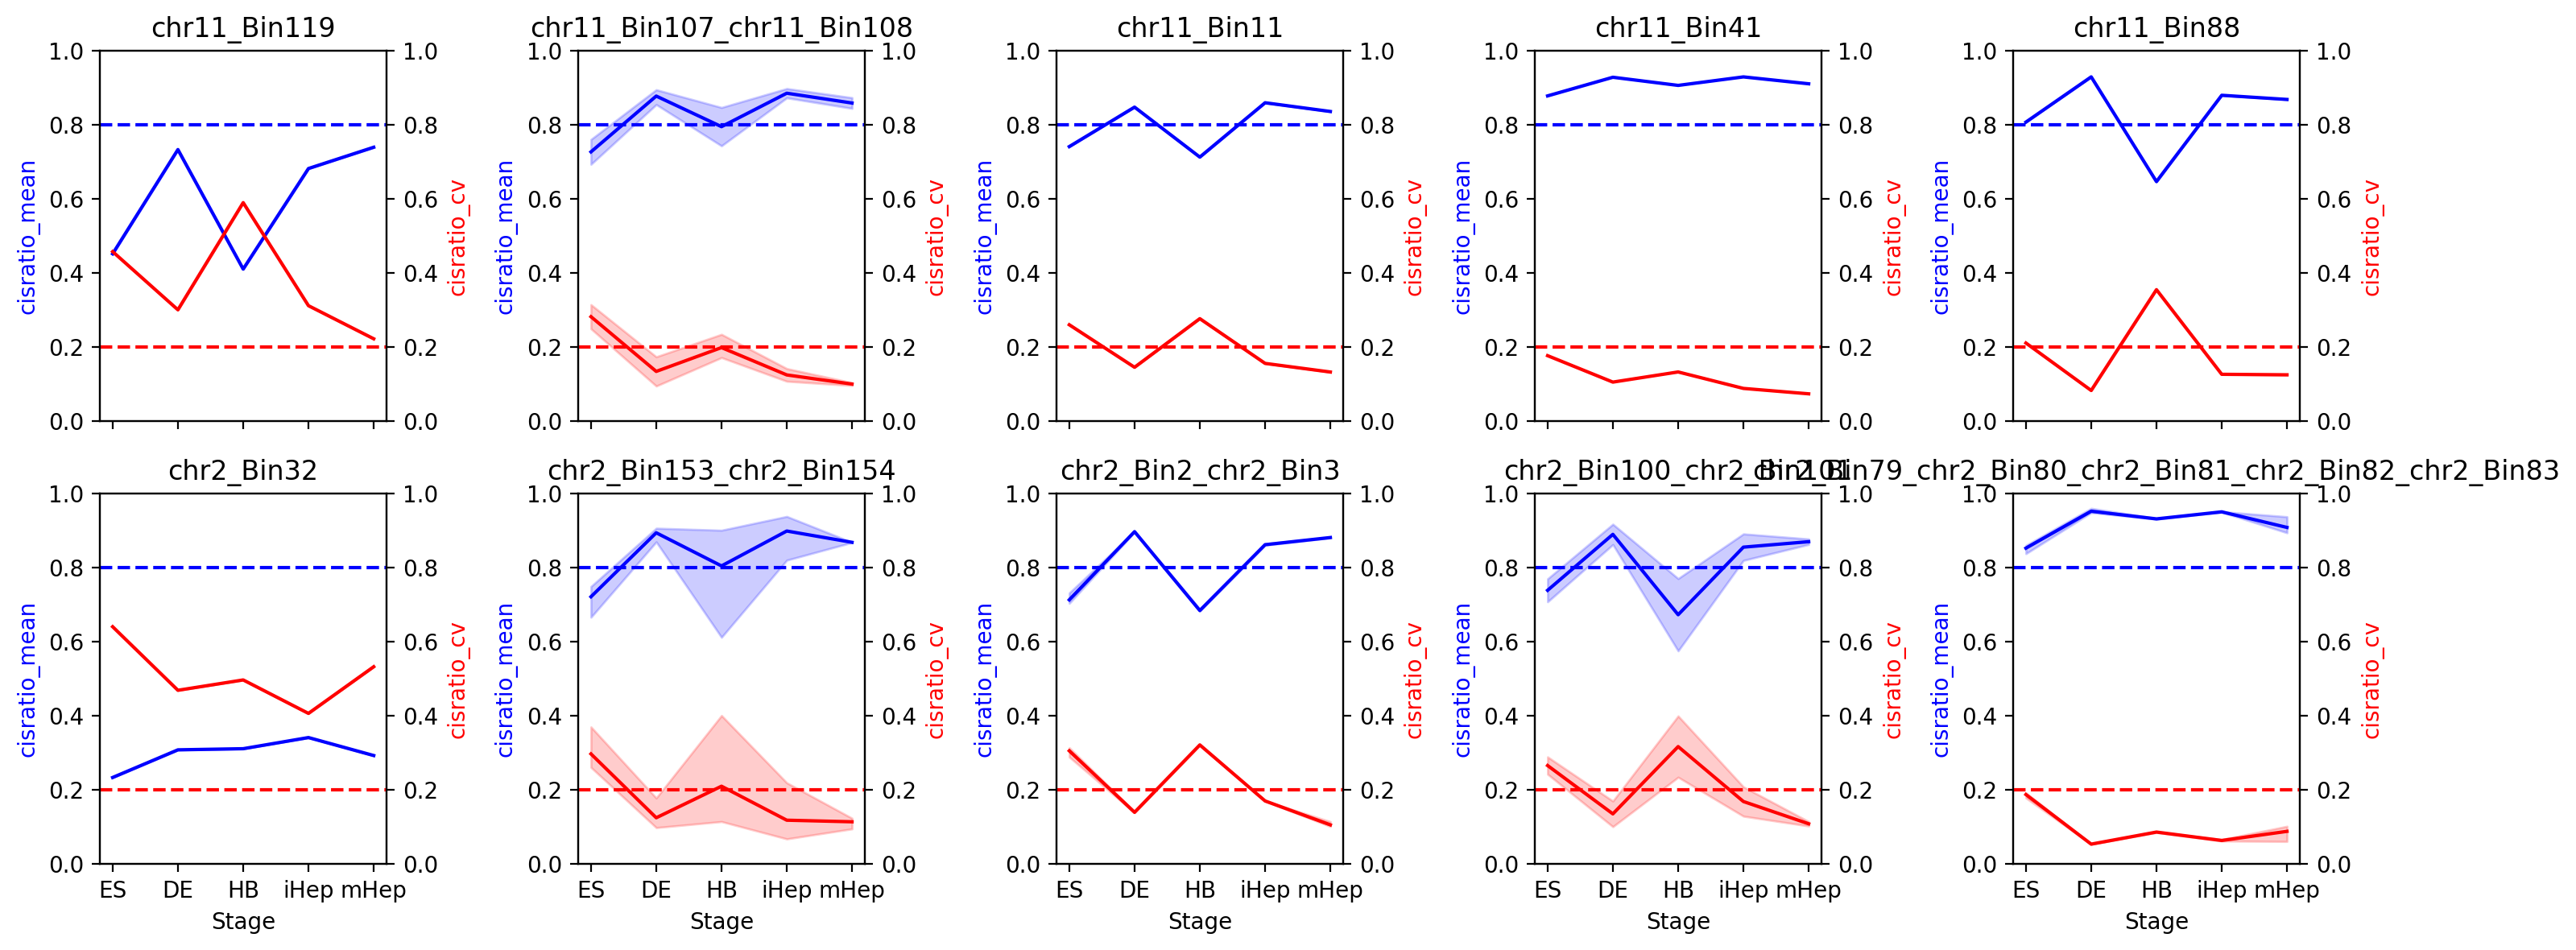

In [6]:
# plot them in the same figure
# Define the two groups of loci based on the desired order
first_line = ['chr11_Bin119', 'chr11_Bin107_chr11_Bin108', 'chr11_Bin11', 'chr11_Bin41', 'chr11_Bin88']
second_line = ['chr2_Bin32', 'chr2_Bin153_chr2_Bin154', 'chr2_Bin2_chr2_Bin3', 'chr2_Bin100_chr2_Bin101', 'chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83']

# Create the figure and subplots (two rows, five columns)
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 6), dpi=200, sharex=True)

# Plot the first line (row index 0)
for col, locus in enumerate(first_line):
    if locus in loci_data:
        data = loci_data[locus].copy()
        data.replace([np.inf, -np.inf], np.nan, inplace=True)

        # Ensure 'cisratio_cv' is numeric
        data['cisratio_cv'] = pd.to_numeric(data['cisratio_cv'], errors='coerce')

        # Create twin axes for second y-axis
        ax1 = axes[0, col]  # Left y-axis for cisratio_mean
        ax2 = ax1.twinx()  # Right y-axis for cisratio_cv

        # Plot cisratio_mean (blue lines)
        sns.lineplot(data=data, x='stage', y='cisratio_mean', ax=ax1, color="blue")
        ax1.axhline(y=0.8, color='blue', linestyle='--')  # Reference line at 0.75
        ax1.set_ylabel("cisratio_mean", color="blue")
        ax1.set_ylim(0, 1)

        # Plot cisratio_cv (red lines)
        sns.lineplot(data=data, x='stage', y='cisratio_cv', ax=ax2, color="red")
        ax2.axhline(y=0.2, color='red', linestyle='--')  # Reference line at 0.25
        ax2.set_ylabel("cisratio_cv", color="red")
        ax2.set_ylim(0, 1)

        # Titles and labels
        ax1.set_title(f'{locus}')
        ax1.set_xlabel("Stage")

# Plot the second line (row index 1)
for col, locus in enumerate(second_line):
    if locus in loci_data:
        data = loci_data[locus].copy()
        data.replace([np.inf, -np.inf], np.nan, inplace=True)

        # Ensure 'cisratio_cv' is numeric
        data['cisratio_cv'] = pd.to_numeric(data['cisratio_cv'], errors='coerce')

        # Create twin axes for second y-axis
        ax1 = axes[1, col]  # Left y-axis for cisratio_mean
        ax2 = ax1.twinx()  # Right y-axis for cisratio_cv

        # Plot cisratio_mean (blue lines)
        sns.lineplot(data=data, x='stage', y='cisratio_mean', ax=ax1, color="blue")
        ax1.axhline(y=0.8, color='blue', linestyle='--')  # Reference line at 0.75
        ax1.set_ylabel("cisratio_mean", color="blue")
        ax1.set_ylim(0, 1)

        # Plot cisratio_cv (red lines)
        sns.lineplot(data=data, x='stage', y='cisratio_cv', ax=ax2, color="red")
        ax2.axhline(y=0.2, color='red', linestyle='--')  # Reference line at 0.25
        ax2.set_ylabel("cisratio_cv", color="red")
        ax2.set_ylim(0, 1)

        # Titles and labels
        ax1.set_title(f'{locus}')
        ax1.set_xlabel("Stage")

# Adjust layout
plt.tight_layout()

# Save the figure
plot_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Cistotal_mean_cv_10loci2.pdf"
plt.savefig(plot_path, format="pdf", bbox_inches="tight")

# Display the figure
plt.show()